In [32]:
import sys
#import torch
import mne
#import braindecode
import sklearn
from mne.decoding import CSP
from pathlib import Path

import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix
"""
MOABB0 -> standardized access to BCI competition dataset

"""

print("Python:", sys.version)
#print("PyTorch:", torch.__version__)
print("MNE:", mne.__version__)
#print("Braindecode:", braindecode.__version__)
print("scikit-learn:", sklearn.__version__)




Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
MNE: 1.11.0
scikit-learn: 1.6.1


# Load cleaned participant epochs

Enter the name of one cleaned epoch file, such as `3076_clean-epo.fif`. The notebook will use that participant's scalp EEG trials for the complete FBCSP + LDA workflow below.

In [33]:
from pathlib import Path

import mne
import numpy as np

# ===== Change this filename for the participant you want to classify. =====
epochs_filename = "3087_clean-epo.fif"

notebook_folder = Path.cwd()
project_folder = notebook_folder.parent
processed_data_folder = project_folder / "data" / "processed"

available_epoch_files = sorted(
    processed_data_folder.glob("*_clean-epo.fif")
)

if not available_epoch_files:
    raise FileNotFoundError(
        f"No cleaned epoch files found in {processed_data_folder}"
    )

print("Available cleaned epoch files:")
for available_file in available_epoch_files:
    print(f"  - {available_file.name}")

if not epochs_filename.strip():
    raise ValueError("Set epochs_filename to one cleaned epoch filename.")

# Use only the filename so the notebook always loads from data/processed.
epochs_file = processed_data_folder / Path(epochs_filename.strip()).name

if not epochs_file.exists():
    raise FileNotFoundError(
        f"Could not find {epochs_file.name} in {processed_data_folder}"
    )

participant_id = epochs_file.name.removesuffix("_clean-epo.fif")

print(f"\nLoading participant {participant_id}: {epochs_file.name}")

# Load saved epochs, not raw continuous EEG.
epochs = mne.read_epochs(
    epochs_file,
    preload=True,
)

# Extract scalp EEG only; EOG channels are excluded.
X = epochs.get_data(picks="eeg")

# Convert numeric event codes to the two trial labels.
y = np.where(
    epochs.events[:, 2] == epochs.event_id["correct_new"],
    "correct_new",
    "correct_old",
)

print(epochs)
print("X shape:", X.shape)
print("Class counts:", np.unique(y, return_counts=True))


Available cleaned epoch files:
  - 3076_clean-epo.fif
  - 3087_clean-epo.fif

Loading participant 3087: 3087_clean-epo.fif
Reading /Users/reedsussman/Desktop/thapar_lab/data/processed/3087_clean-epo.fif ...
    Found the data of interest:
        t =    -200.00 ...    1500.00 ms
        0 CTF compensation matrices available
Not setting metadata
242 matching events found
No baseline correction applied
0 projection items activated
<EpochsFIF | 242 events (all good), -0.2 – 1.5 s (baseline -0.2 – 0 s), ~28.4 MiB, data loaded,
 'correct_old': 123
 'correct_new': 119>
X shape: (242, 32, 426)
Class counts: (array(['correct_new', 'correct_old'], dtype='<U11'), array([119, 123]))


## Split the Data into a Training Set and a Testing Set

The data is naturally spaced so there are three blocks within. We can distingish the three blocks by examining the time between successive events (if there are greater than 60 seconds between to events / start of two epochs, a new block is about to start)

So, we will identify which epochs correspond to each block, train on the first two, and test on the third. 

In [34]:
#training and testing

#get sampling rate
sampling_rate = epochs.info["sfreq"]

#get starting sample number of each epoch
event_samples = epochs.events[:, 0]

#convert starting sample number of each epoch time seconds
event_time_seconds = (
    event_samples / sampling_rate
)


recording_block_numbers = []

#start with block zero
current_block = 0
previous_event_time = None

for current_event_time in event_time_seconds:

    #assuming we aren't on the first epoch
    if previous_event_time is not None:

        #calculate the time gap (see if we are starting a new block)
        time_gap_seconds = current_event_time - previous_event_time

        #long pause indicates a new recording block 
        if time_gap_seconds > 60:
            current_block +=1
    
    #track which block this epoch corresponds too (will have same index)
    recording_block_numbers.append(current_block)

    
    previous_event_time = current_event_time


recording_block_numbers = np.array(
    recording_block_numbers
)

#look at all of the block numbers, count how many trials are in each block
for block_number in np.unique(recording_block_numbers):
    number_of_trials = np.sum(
        recording_block_numbers == block_number
    )

    print(
        f"Block {block_number}: "
        f"{number_of_trials} trials"
    )

# Use every block before the final block for development/training.
final_test_block_number = recording_block_numbers.max()
development_trial_index = np.flatnonzero(
    recording_block_numbers < final_test_block_number
)

# Use the final recording block as the chronological test set.
final_test_trial_index = np.flatnonzero(
    recording_block_numbers == final_test_block_number
)

#train on first two blocks, test on the last block
X_train = X[development_trial_index]
X_test = X[final_test_trial_index]

"""

# Keep only 0.0–0.8 seconds after stimulus onset
time_mask = (
    (epochs.times >= 0.0)
    & (epochs.times <= 0.8)
)

X_train = X_train[:, :, time_mask]
X_test = X_test[:, :, time_mask]

print("Time range:", epochs.times[time_mask][0],
      "to", epochs.times[time_mask][-1])
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
"""
#labels
y_train = y[development_trial_index]
y_test = y[final_test_trial_index]

print("Training trials:", len(X_train))
print("Final-test trials:", len(X_test))

Block 0: 88 trials
Block 1: 84 trials
Block 2: 70 trials
Training trials: 172
Final-test trials: 70


In [35]:

frequency_bands = [
    [2, 4],    # delta
    [4, 8],    # theta
    [8, 12],   # alpha
    [12, 20],  # low beta
    [20,25], #explore?
    [25,30]
]

def filter_one_frequency_band(eeg_data, low_frequency, high_frequency):
    filtered_data = mne.filter.filter_data(
        eeg_data.copy(),
        sfreq=sampling_rate,
        l_freq=low_frequency,
        h_freq=high_frequency,
        method="iir",
        iir_params={
            "order":4,
            "ftype":"butter",
        },
        verbose="ERROR",  
    )

    return filtered_data


training_bands = []
testing_bands = []
for low_frequency, high_frequency in frequency_bands:
    filtered_training_data = filter_one_frequency_band(
        X_train,
        low_frequency,
        high_frequency,
    )


    filtered_testing_data = filter_one_frequency_band(
        X_test,
        low_frequency,
        high_frequency,
    )

    training_bands.append(filtered_training_data)
    testing_bands.append(filtered_testing_data)

X_train_fb = np.stack(
    training_bands,
    axis=-1,
)

X_test_fb = np.stack(
    testing_bands,
    axis=-1,
)

print("Training filter-bank shape:", X_train_fb.shape)
#Expected (134 training trials, 32 channels, 426 time points per trial, 10 bands)
print("Testing filter-bank shape:", X_test_fb.shape)
#Expected (62 testing trials, 32 channels, 426 time points per trial, 10 bands)






Training filter-bank shape: (172, 32, 426, 6)
Testing filter-bank shape: (70, 32, 426, 6)


## Learn CSP weights / extract features for each frequency band

In [36]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
)
from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
)

train_features_by_band = []
test_features_by_band = []
csp_models = []

for band_index in range((len(frequency_bands))):

  #extract only the frequency range desired
  band_train = X_train_fb[:, :, :, band_index]
  band_test = X_test_fb[:, :, :, band_index]

  #same as before, but we do it for each frequency band
  csp = CSP(
        n_components=4,
        reg="oas",
        log=True,
    )
  #learn weights
  train_features = csp.fit_transform(
        band_train,
        y_train,
    )
  #use weights we learned from training
  test_features = csp.transform(
        band_test,
    )


  train_features_by_band.append(train_features) #train features is 144 trials x 4 features
  test_features_by_band.append(test_features) #same thing for test features
  csp_models.append(csp) #stores the CSP model (different one for each band)


  """
  train_features_by_band should have a list containing 7 arrays
  each array should be shaped 144x4 (144 trials, 4 log variance values for each trial in each band)

  """

#concatenate such that each trial gets 28 features
#axis 1 so (144,4) + (144, 4) + ... = (144,28)

"""
Ordinary CSP filters the EEG signal into one broad frequency range, learns spatial filters from that signal,
and passes the resulting log-variance features to a classifier

FBCSP divdes the EEG into multiple frequency bands, learns an independent CSP model within each band,
concatenates the CSP features from each band, selects the most informative features (those that maximize
the difference between classes), and passes those selected features to a classifier


"""

X_train_fbcsp = np.concatenate(
    train_features_by_band,
    axis=1,
)


X_test_fbcsp = np.concatenate(
    test_features_by_band,
    axis=1,
)


print(X_train_fbcsp.shape)
#expect (138, 40 features per trial = 10 frequency bands * 4 CSP log-variance featuers per band)
print(X_test_fbcsp.shape)
#expect (62, 40)


Computing rank from data with rank=None
    Using tolerance 4.2e-05 (2.2e-16 eps * 32 dim * 5.9e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_new covariance using OAS
Done.
Estimating class=correct_old covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 3e-05 (2.2e-16 eps * 32 dim * 4.2e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_new covariance using OAS
Done.
Estimating class=correct_old covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 2.4e-05 (2.2e-16 eps * 32 dim * 3.4e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_

## Select the most important features to pass into the model

In [37]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from functools import partial


#select the k best features to pass into classifer (of 28)
selector = SelectKBest(
    score_func=partial(
        mutual_info_classif,
        random_state=42,
    ),
    k=8,
)

X_train_selected = selector.fit_transform(
    X_train_fbcsp,
    y_train,
)

X_test_selected = selector.transform(
    X_test_fbcsp,
)
#expect (134 x 8 best features)
print(X_train_selected.shape)

print(X_test_selected.shape)

(172, 8)
(70, 8)


## Train LDA model with most important features

In [38]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
)

lda = LinearDiscriminantAnalysis()

lda.fit(
    X_train_selected,
    y_train,
)

fbcsp_predictions = lda.predict(
    X_test_selected
)

fbcsp_accuracy = accuracy_score(
    y_test,
    fbcsp_predictions,
)

fbcsp_balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        fbcsp_predictions,
    )
)

fbcsp_confusion_matrix = confusion_matrix(
    y_test,
    fbcsp_predictions,
    labels=[
        "correct_old",
        "correct_new",
    ],
)

print(
    "FBCSP + LDA accuracy:",
    f"{fbcsp_accuracy:.3f}",
)

print(
    "FBCSP + LDA balanced accuracy:",
    f"{fbcsp_balanced_accuracy:.3f}",
)

print(
    "Confusion matrix:",
)

print(fbcsp_confusion_matrix)

FBCSP + LDA accuracy: 0.643
FBCSP + LDA balanced accuracy: 0.596
Confusion matrix:
[[37  3]
 [22  8]]


## Output what features (which CSP components of which frequencies) are most important

In [39]:
selected_indices = selector.get_support(indices=True)
full_epoch_selected_features = []

for feature_index in selected_indices:
    band_index = feature_index // 4
    component_index = feature_index % 4
    low_frequency, high_frequency = frequency_bands[band_index]
    feature_label = (
        f"{low_frequency}–{high_frequency} Hz · "
        f"CSP {component_index + 1}"
    )
    full_epoch_selected_features.append(feature_label)
    print(feature_label)


old_recall = (
    fbcsp_confusion_matrix[0, 0]
    / fbcsp_confusion_matrix[0].sum()
)
new_recall = (
    fbcsp_confusion_matrix[1, 1]
    / fbcsp_confusion_matrix[1].sum()
)

full_epoch_result = {
    "name": "Full epoch",
    "time_range": (
        f"{epochs.times[0]:.1f} to {epochs.times[-1]:.1f} s"
    ),
    "frequency_bands": ", ".join(
        [f"{low}–{high}" for low, high in frequency_bands]
    ) + " Hz",
    "confusion_matrix": fbcsp_confusion_matrix.copy(),
    "accuracy": fbcsp_accuracy,
    "balanced_accuracy": fbcsp_balanced_accuracy,
    "recall": np.array([old_recall, new_recall]),
    "selected_features": full_epoch_selected_features,
}

print("\nConfusion matrix:")
print(fbcsp_confusion_matrix)
print("correct_old recall:", old_recall)
print("correct_new recall:", new_recall)


4–8 Hz · CSP 3
8–12 Hz · CSP 1
12–20 Hz · CSP 1
12–20 Hz · CSP 2
12–20 Hz · CSP 3
20–25 Hz · CSP 1
25–30 Hz · CSP 1
25–30 Hz · CSP 3

Confusion matrix:
[[37  3]
 [22  8]]
correct_old recall: 0.925
correct_new recall: 0.26666666666666666


## Compare early, middle, and late FBCSP windows

Each window is 0.8 seconds long and uses the same chronological train/test split, CSP settings, feature-selection rule, and LDA classifier. The 2–4 Hz band is excluded here because an 0.8-second window is too short to estimate delta power reliably.

In [40]:
from functools import partial

from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix


window_frequency_bands = [
    [2,4],
    [4, 8],
    [8, 12],
    [12, 20],
    [20, 25],
    [25, 30],
]

window_definitions = {
    "early_window": ("Early window", 0.0, 0.8),
    "middle_window": ("Middle window", 0.4, 1.2),
    "late_window": ("Late window", 0.7, 1.5),
}


def run_fbcsp_for_time_window(window_name, minimum_time, maximum_time):
    """Fit FBCSP + LDA on Blocks 0+1 and evaluate on Block 2."""
    time_mask = (
        (epochs.times >= minimum_time)
        & (epochs.times <= maximum_time)
    )

    window_training_data = X[development_trial_index][:, :, time_mask]
    window_testing_data = X[final_test_trial_index][:, :, time_mask]
    window_training_labels = y[development_trial_index]
    window_testing_labels = y[final_test_trial_index]

    training_bands = []
    testing_bands = []

    for low_frequency, high_frequency in window_frequency_bands:
        filter_parameters = {"order": 4, "ftype": "butter"}

        training_bands.append(
            mne.filter.filter_data(
                window_training_data.copy(),
                sfreq=epochs.info["sfreq"],
                l_freq=low_frequency,
                h_freq=high_frequency,
                method="iir",
                iir_params=filter_parameters,
                verbose="ERROR",
            )
        )
        testing_bands.append(
            mne.filter.filter_data(
                window_testing_data.copy(),
                sfreq=epochs.info["sfreq"],
                l_freq=low_frequency,
                h_freq=high_frequency,
                method="iir",
                iir_params=filter_parameters,
                verbose="ERROR",
            )
        )

    training_filter_bank = np.stack(training_bands, axis=-1)
    testing_filter_bank = np.stack(testing_bands, axis=-1)

    training_features_by_band = []
    testing_features_by_band = []

    for band_index in range(len(window_frequency_bands)):
        csp = CSP(
            n_components=4,
            reg="oas",
            log=True,
        )
        training_features_by_band.append(
            csp.fit_transform(
                training_filter_bank[:, :, :, band_index],
                window_training_labels,
            )
        )
        testing_features_by_band.append(
            csp.transform(
                testing_filter_bank[:, :, :, band_index],
            )
        )

    training_fbcsp_features = np.concatenate(
        training_features_by_band,
        axis=1,
    )
    testing_fbcsp_features = np.concatenate(
        testing_features_by_band,
        axis=1,
    )

    selector = SelectKBest(
        score_func=partial(
            mutual_info_classif,
            random_state=42,
        ),
        k=8,
    )
    selected_training_features = selector.fit_transform(
        training_fbcsp_features,
        window_training_labels,
    )
    selected_testing_features = selector.transform(
        testing_fbcsp_features,
    )

    classifier = LinearDiscriminantAnalysis()
    classifier.fit(
        selected_training_features,
        window_training_labels,
    )
    predictions = classifier.predict(selected_testing_features)

    matrix = confusion_matrix(
        window_testing_labels,
        predictions,
        labels=["correct_old", "correct_new"],
    )
    selected_features = []

    for feature_index in selector.get_support(indices=True):
        band_index = feature_index // 4
        component_index = feature_index % 4
        low_frequency, high_frequency = window_frequency_bands[band_index]
        selected_features.append(
            f"{low_frequency}–{high_frequency} Hz · CSP {component_index + 1}"
        )

    return {
        "name": window_name,
        "time_range": f"{minimum_time:.1f} to {maximum_time:.1f} s",
        "frequency_bands": "4–8, 8–12, 12–20, 20–25, 25–30 Hz",
        "confusion_matrix": matrix,
        "accuracy": accuracy_score(window_testing_labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            window_testing_labels,
            predictions,
        ),
        "recall": np.diag(matrix) / matrix.sum(axis=1),
        "selected_features": selected_features,
    }


window_results = {}

for result_key, (window_name, minimum_time, maximum_time) in window_definitions.items():
    window_results[result_key] = run_fbcsp_for_time_window(
        window_name,
        minimum_time,
        maximum_time,
    )

    result = window_results[result_key]
    print(f"\n{result['name']} ({result['time_range']})")
    print(f"Accuracy: {result['accuracy']:.3f}")
    print(f"Balanced accuracy: {result['balanced_accuracy']:.3f}")
    print("Confusion matrix:")
    print(result["confusion_matrix"])
    print(
        "Recall — correct_old: "
        f"{result['recall'][0]:.3f}; "
        "correct_new: "
        f"{result['recall'][1]:.3f}"
    )


Computing rank from data with rank=None
    Using tolerance 3e-05 (2.2e-16 eps * 32 dim * 4.2e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_new covariance using OAS
Done.
Estimating class=correct_old covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 2.1e-05 (2.2e-16 eps * 32 dim * 3e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_new covariance using OAS
Done.
Estimating class=correct_old covariance using OAS
Done.
Computing rank from data with rank=None
    Using tolerance 1.7e-05 (2.2e-16 eps * 32 dim * 2.4e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=correct_ne

## FBCSP + LDA experiment summary

After running the full-epoch and early/middle/late-window cells for the selected filename, this graphic summarizes the selected participant's time ranges, training-selected CSP features, accuracy, balanced accuracy, class recall, and confusion matrices.

Saved graphic: /Users/reedsussman/Desktop/thapar_lab/results/figures/fbcsp_lda/3087_fbcsp_lda_time_window_comparison.png


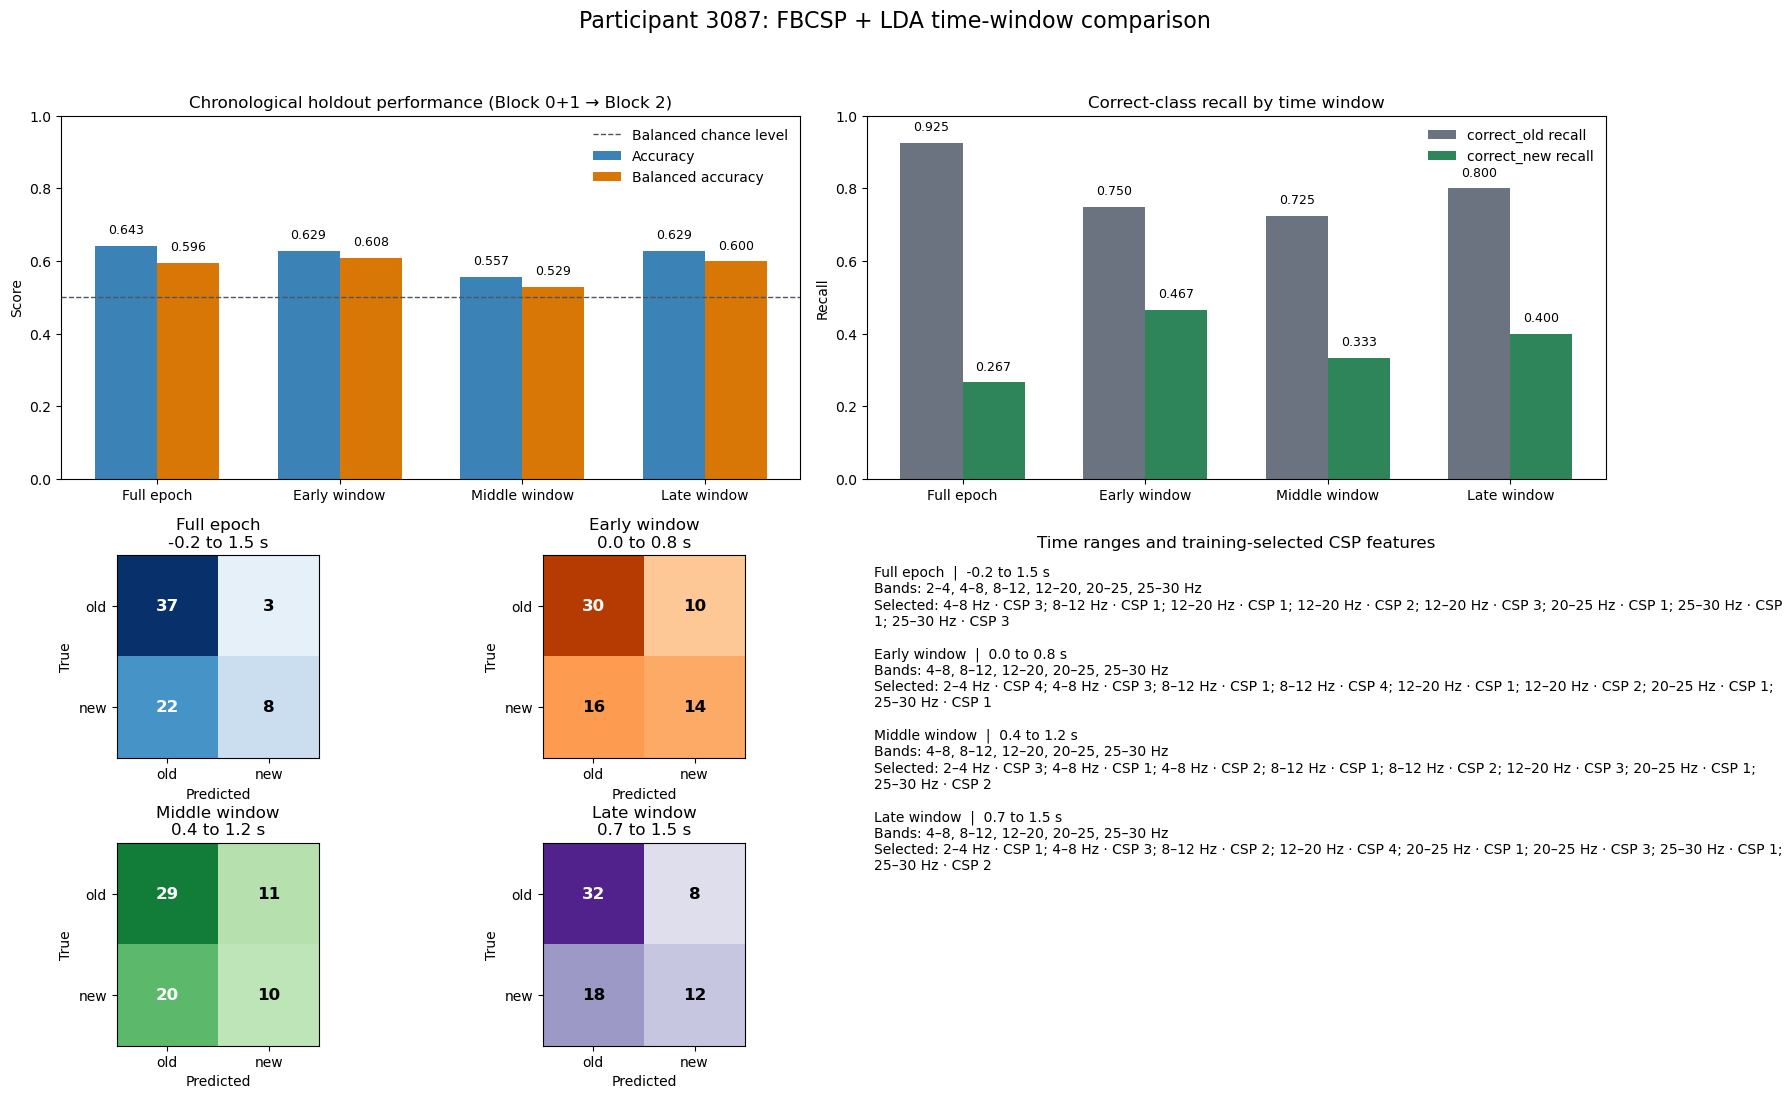

In [41]:
from pathlib import Path

import matplotlib.pyplot as plt


if "full_epoch_result" not in globals():
    raise RuntimeError(
        "Run the full-epoch feature-summary cell before this graphic cell."
    )

if "window_results" not in globals():
    raise RuntimeError(
        "Run the early/middle/late window comparison cell before this graphic cell."
    )

experiment_results = {"full_epoch": full_epoch_result, **window_results}
model_keys = list(experiment_results)
model_names = [experiment_results[key]["name"] for key in model_keys]
positions = np.arange(len(model_keys))


figure = plt.figure(figsize=(18, 11))
grid = figure.add_gridspec(2, 2, height_ratios=[1, 1.35])


# Accuracy and balanced accuracy
performance_axis = figure.add_subplot(grid[0, 0])
bar_width = 0.34
accuracy_bars = performance_axis.bar(
    positions - bar_width / 2,
    [experiment_results[key]["accuracy"] for key in model_keys],
    bar_width,
    label="Accuracy",
    color="#3B82B6",
)
balanced_bars = performance_axis.bar(
    positions + bar_width / 2,
    [experiment_results[key]["balanced_accuracy"] for key in model_keys],
    bar_width,
    label="Balanced accuracy",
    color="#D97706",
)
performance_axis.axhline(
    0.5,
    color="#4B5563",
    linestyle="--",
    linewidth=1,
    label="Balanced chance level",
)
performance_axis.set(
    title="Chronological holdout performance (Block 0+1 → Block 2)",
    xticks=positions,
    xticklabels=model_names,
    ylabel="Score",
    ylim=(0, 1),
)
performance_axis.legend(frameon=False, loc="upper right")

for bars in [accuracy_bars, balanced_bars]:
    for bar in bars:
        performance_axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.025,
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )


# Correct-old and correct-new recall
recall_axis = figure.add_subplot(grid[0, 1])
recall_width = 0.34
old_recall_bars = recall_axis.bar(
    positions - recall_width / 2,
    [experiment_results[key]["recall"][0] for key in model_keys],
    recall_width,
    label="correct_old recall",
    color="#6B7280",
)
new_recall_bars = recall_axis.bar(
    positions + recall_width / 2,
    [experiment_results[key]["recall"][1] for key in model_keys],
    recall_width,
    label="correct_new recall",
    color="#2F855A",
)
recall_axis.set(
    title="Correct-class recall by time window",
    xticks=positions,
    xticklabels=model_names,
    ylabel="Recall",
    ylim=(0, 1),
)
recall_axis.legend(frameon=False, loc="upper right")

for bars in [old_recall_bars, new_recall_bars]:
    for bar in bars:
        recall_axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.025,
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )


# Four confusion matrices
matrix_grid = grid[1, 0].subgridspec(2, 2, wspace=0.36, hspace=0.42)
for axis, key, colormap in zip(
    [
        figure.add_subplot(matrix_grid[0, 0]),
        figure.add_subplot(matrix_grid[0, 1]),
        figure.add_subplot(matrix_grid[1, 0]),
        figure.add_subplot(matrix_grid[1, 1]),
    ],
    model_keys,
    ["Blues", "Oranges", "Greens", "Purples"],
):
    result = experiment_results[key]
    matrix = result["confusion_matrix"]
    axis.imshow(matrix, cmap=colormap, vmin=0, vmax=36)

    for row_index in range(2):
        for column_index in range(2):
            text_color = "white" if matrix[row_index, column_index] > 18 else "black"
            axis.text(
                column_index,
                row_index,
                matrix[row_index, column_index],
                ha="center",
                va="center",
                color=text_color,
                fontsize=12,
                fontweight="bold",
            )

    axis.set(
        title=f"{result['name']}\n{result['time_range']}",
        xticks=[0, 1],
        xticklabels=["old", "new"],
        yticks=[0, 1],
        yticklabels=["old", "new"],
        xlabel="Predicted",
        ylabel="True",
    )


# Time ranges and selected CSP features
feature_axis = figure.add_subplot(grid[1, 1])
feature_axis.axis("off")
feature_axis.set_title("Time ranges and training-selected CSP features")

summary_text = []
for key in model_keys:
    result = experiment_results[key]
    summary_text.extend(
        [
            f"{result['name']}  |  {result['time_range']}",
            f"Bands: {result['frequency_bands']}",
            f"Selected: {'; '.join(result['selected_features'])}",
            "",
        ]
    )

feature_axis.text(
    0.01,
    0.98,
    "\n".join(summary_text),
    transform=feature_axis.transAxes,
    va="top",
    fontsize=10,
    wrap=True,
)

figure.suptitle(
    f"Participant {participant_id}: FBCSP + LDA time-window comparison",
    fontsize=16,
    y=0.995,
)
figure.tight_layout(rect=(0, 0, 1, 0.965))

notebook_folder = Path.cwd()
project_folder = notebook_folder.parent
figure_folder = project_folder / "results" / "figures" / "fbcsp_lda"
figure_folder.mkdir(parents=True, exist_ok=True)
figure_path = figure_folder / (
    f"{participant_id}_fbcsp_lda_time_window_comparison.png"
)
figure.savefig(figure_path, dpi=300, bbox_inches="tight")

print(f"Saved graphic: {figure_path}")
plt.show()
